In [44]:
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPool2D, Flatten, BatchNormalization, Dropout
import matplotlib.pyplot as plt
import cv2
import numpy as np

In [16]:
import zipfile
zip_ref = zipfile.ZipFile('/content/hiragana_train_test.zip')
zip_ref.extractall()
zip_ref.close()

In [32]:
training_ds = keras.utils.image_dataset_from_directory(
    directory='/content/train',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(64, 64),
    color_mode='grayscale'
)

testing_ds = keras.utils.image_dataset_from_directory(
    directory='/content/test',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(64, 64),
    color_mode='grayscale'
)

import json

with open('/content/hiragana_classes.json', 'w', encoding='utf-8') as f:
    json.dump(training_ds.class_names, f, ensure_ascii=False)

Found 3680 files belonging to 46 classes.
Found 920 files belonging to 46 classes.


In [33]:
def process(image, label):
  image = tf.cast(image/255. , tf.float32)
  return image, label

training_ds = training_ds.map(process)
testing_ds = testing_ds.map(process)

In [34]:
model = Sequential()

# Input: 64 x 64 grayscale
model.add(Conv2D(32, (3,3), padding='same',
                 activation='relu',
                 input_shape=(64,64,1)))
model.add(BatchNormalization())
model.add(MaxPool2D((2,2)))

# 32 x 32
model.add(Conv2D(64, (3,3), padding='same',
                 activation='relu'))
model.add(BatchNormalization())
model.add(MaxPool2D((2,2)))

# 16 x 16
model.add(Conv2D(128, (3,3), padding='same',
                 activation='relu'))
model.add(BatchNormalization())
model.add(MaxPool2D((2,2)))

# 8 x 8
model.add(Conv2D(256, (3,3), padding='same',
                 activation='relu'))
model.add(BatchNormalization())
model.add(MaxPool2D((2,2)))

# 4 x 4
model.add(Flatten())

model.add(Dense(256, activation='relu'))
model.add(Dropout(0.3))

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.3))

# 46 Hiragana classes
model.add(Dense(46, activation='softmax'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_13 (Conv2D)              │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 46)             │         5,934 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,477,422 (5.64 MB)

 Trainable params: 1,476,462 (5.63 MB)

 Non-trainable params: 960 (3.75 KB)

In [35]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
history = model.fit(training_ds, epochs=15, validation_data=testing_ds)

Epoch 1/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 61s 495ms/step - accuracy: 0.4973 - loss: 1.9870 - val_accuracy: 0.0370 - val_loss: 6.6631
Epoch 2/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 58s 503ms/step - accuracy: 0.9033 - loss: 0.3173 - val_accuracy: 0.0587 - val_loss: 9.7360
Epoch 3/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 59s 512ms/step - accuracy: 0.9462 - loss: 0.1632 - val_accuracy: 0.1500 - val_loss: 8.1688
Epoch 4/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 79s 485ms/step - accuracy: 0.9609 - loss: 0.1197 - val_accuracy: 0.8380 - val_loss: 0.4621
Epoch 5/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 55s 481ms/step - accuracy: 0.9707 - loss: 0.0889 - val_accuracy: 0.9989 - val_loss: 0.0044
Epoch 6/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 82s 479ms/step - accuracy: 0.9780 - loss: 0.0793 - val_accuracy: 1.0000 - val_loss: 3.7961e-04
Epoch 7/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 58s 502ms/step - accuracy: 0.9799 - loss: 0.0640 - val_accuracy: 1.0000 - val_loss: 5.6577e-04
Epoch 8/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 58s 502ms/step - accuracy: 0.9804 -

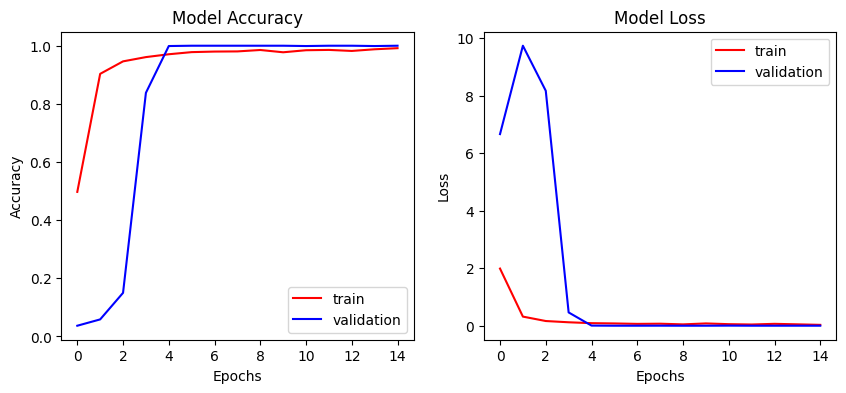

In [36]:
import os
# ==========================================
# 6. EVALUATION (LOSS & ACCURACY PLOTS)
# ==========================================
# Plot Accuracy
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], color='red', label='train')
plt.plot(history.history['val_accuracy'], color='blue', label='validation')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], color='red', label='train')
plt.plot(history.history['val_loss'], color='blue', label='validation')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [39]:
model.save('/content/hiragana_model.keras')

In [42]:
from google.colab import files

files.download('/content/hiragana_model.keras')
files.download('/content/hiragana_classes.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:

with open('hiragana_classes.json', 'r', encoding='utf-8') as f:
    class_names = json.load(f)

for images, labels in testing_ds.take(1):

    test_image = images[0].numpy()
    true_label = labels[0].numpy()

    test_input = np.expand_dims(test_image, axis=0)

    prediction = model.predict(test_input, verbose=0)

    predicted_class = np.argmax(prediction[0])
    confidence = np.max(prediction[0])

    print("Actual:", class_names[true_label])
    print("Predicted:", class_names[predicted_class])
    print("Confidence:", confidence)

Actual: ke
Predicted: ke
Confidence: 0.99999976
